---
title: "Getting Started with Unitaria: Basic Matrices and Block Encodings"
author:
    - name: Ram Mosco
date: "2026-04-05"
categories: [basics, linear algebra, block encodings]
image: "preview.png"
format:
  html:
    code-fold: false
    toc: true
    cap-location: bottom
jupyter: unitaria
code-annotations: hover
---


Quantum algorithms process data through unitary operations ($U^\dagger U = I$). However, not all matrices in quantum computing use cases are unitary.

To work with arbitrary matrices $A \in \mathbb{C}^{m \times n}$ on quantum computers, we use block encodings, which means embedding $A$ as a sub-block of a larger unitary operator $U$.

$$\begin{equation}
U = \begin{bmatrix} A / \alpha & * \\ * & * \end{bmatrix}
\end{equation}$$

Here:

- $\alpha \ge \|A\|_2$ is a real normalization factor that scales the matrix so that $\|A / \alpha\|_2 \le 1$. 

- The asterisks $*$ represent filler matrix elements that ensure $U$ remains unitary $U^\dagger U = I$.

- The sub-block is selected by specifying input and output subspaces

While the theory of block encodings is well known, constructing the corresponding quantum circuits manually involves tedious gate synthesis and ancilla bookkeeping. `unitaria` abstracts this away by providing an operator-based interface modeled after NumPy and SciPy.

We begin with the standard imports:


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import unitaria as ut

np.set_printoptions(precision=3, suppress=True)


## 1. Elementary Nodes

Unitaria represents matrices, vectors, and operations as subclasses of `Node`.

### The Identity Node

The `Identity` node represents the $d \times d$ identity matrix on $\lceil \log_2 d \rceil$ qubits:


In [2]:
I = ut.Identity(dim=4)
print(I)
print(I.toarray())
print("Active basis indices:", I.subspace_in.enumerate_basis())


Identity{'subspace': Subspace("##")}
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]]
Active basis indices: [0 1 2 3]


### Subspace Masks: `"##"` vs `"0#"`

Notice the descriptor `Identity{'subspace': Subspace("##")}`. A 4-dimensional matrix requires $\lceil \log_2 4 \rceil = 2$ qubits ($2^2 = 4$ total basis states: $|00\rangle, |01\rangle, |10\rangle, |11\rangle$).

In Unitaria, `'#'` and `'0'` act as masks on each qubit:

- `'#'` denotes an unconstrained data qubit, which can freely be in state $|0\rangle$ or $|1\rangle$).

- `'0'` denotes an ancilla helper qubit, that is constrained to the state $|0\rangle$.

Comparing the two:

- **`Subspace("##")`** as in the $4 \times 4$ identity matrix, both qubits hold data. All 4 basis states are active (`[0, 1, 2, 3]`), so the subspace dimension is $4$.

- **`Subspace("0#")`** when one ancilla is present, the first qubit is constrained to $|0\rangle$, while the second qubit holds data. Only states $|00\rangle$ (index 0) and $|01\rangle$ (index 1) are active, shrinking the effective subspace size from 4 down to 2 states. Any amplitude landing on $|10\rangle$ or $|11\rangle$ corresponds to the ancilla being $|1\rangle$ and is discarded by the projection.

### The Increment Node

The `Increment` node implements the cyclic permutation / shift operator on $n$ qubits:

$$\begin{equation}
|k\rangle \mapsto |(k+1) \bmod 2^n\rangle
\end{equation}$$

For $n=2$ qubits ($2^2 = 4$ basis states), this corresponds to the $4 \times 4$ cyclic shift matrix with ones on the first subdiagonal and a one in the top-right corner

$$\begin{equation}
X = \begin{bmatrix}
0 & 0 & 0 & 1 \\
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 1 & 0
\end{bmatrix}
\end{equation}$$


In [3]:
X = ut.Increment(bits=2)
print(X.toarray())


[[0.+0.j 0.+0.j 0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]]


### Constant Vectors

We can prepare an arbitrary classical statevector using `ConstantVector`. Unitaria synthesizes a state-preparation circuit that loads the normalized amplitudes:


In [4]:
v = ut.ConstantVector(np.array([1.0, 0.0, 1.0, 0.0]))

print("Encoded vector v:")
print(v.toarray())
print("Normalization factor alpha:", v.normalization)


Encoded vector v:
[1.+0.j 0.+0.j 1.+0.j 0.+0.j]
Normalization factor alpha: 1.4142135623730951


### Constant Matrices

Arbitrary classical matrices can be embedded into a block encoding using `ConstantMatrix`. Unitaria automatically scales the matrix by its spectral norm $\alpha = \|A\|_2$ and synthesizes the underlying unitary circuit:


In [5]:
M = ut.ConstantMatrix(np.array([[1.0, 2.0], [3.0, 4.0]]))

print("Encoded matrix M:")
print(M.toarray())
print("Normalization alpha:", M.normalization)


Encoded matrix M:
[[1.+0.j 2.+0.j]
 [3.+0.j 4.+0.j]]
Normalization alpha: 5.464985704219043


## 2. Inspection and Verification

A central design principle of Unitaria is its dual evaluation architecture

1. **Matrix-arithmetic evaluation**: Methods like `.toarray()` and `.compute()` evaluate operations directly on classical matrices and vectors without simulating quantum statevectors. This enables rapid numerical verification.

2. **Circuit synthesis**: `.circuit()` generates the gate-level quantum circuit (via Tequila), which can then be compiled or simulated with statevector backends such as Qulacs.

We can inspect the properties of any node:


In [6]:
# Normalization factor alpha
print("Normalization alpha:", X.normalization)

# Input and output subspace basis indices
print("Subspace basis:", X.subspace_in.enumerate_basis())


Normalization alpha: 1
Subspace basis: [0 1 2 3]


### Automatic Verification

To verify that the synthesized quantum circuit mathematically implements the intended matrix, Unitaria provides `ut.verify()`. It executes a statevector simulation of the circuit across all basis states and asserts agreement with `.toarray()` up to machine precision:


In [7]:
ut.verify(I)
ut.verify(X)
ut.verify(v)
ut.verify(M)
print("All primitive nodes verified successfully.")


All primitive nodes verified successfully.


### Visualizing Quantum Circuits

We can view the synthesized quantum circuit using `.circuit().draw()`:


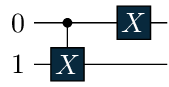

In [8]:
X.circuit().draw()
